# 03 · In-silico perturbations and Mana et al. (2023) priors

Visualises `src/perturbation` output (run `python -m src.perturbation.run`). Higher map values = the perturbation
moves the subject toward the target (healthy mean FC for `p2h_*`, patient mean FC for `p2p_apos`); best node = argmax.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.core import paths
from src.core.data import GROUPS, load_data, load_model_results, load_features

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"HC": "#2a9d8f", "AP": "#e76f51", "NAP": "#e9c46a"}

In [2]:
D = paths.DERIVED / "perturbation"
mr = load_model_results(); res, atlas = mr["results"], mr["atlas"]
labels, network = atlas["labels"], np.array(atlas["network"])
sets = pd.read_csv(D / "mana_sets.csv")
rest = sets.query("set == 'restorative'").node.values; path = sets.query("set == 'pathogenic'").node.values
display(sets)
display(pd.read_csv(D / "mana_tests.csv").round(4))

,set,node,label
0,restorative,0,LH_Vis_1
1,restorative,28,LH_SalVentAttn_Med_2
2,restorative,30,LH_Limbic_OFC_1
3,restorative,36,LH_Cont_Cing_1
4,restorative,41,LH_Default_PFC_1
5,restorative,49,LH_Default_pCunPCC_2
6,restorative,50,RH_Vis_1
7,restorative,76,RH_SalVentAttn_Med_1
8,restorative,78,RH_Limbic_OFC_1
9,restorative,86,RH_Cont_Cing_1


,map,set,subjects,mean_percentile,p_vs_random_sets
0,p2h_noise,restorative,AP+NAP,0.5246,0.3405
1,p2h_noise,restorative,HC,0.5404,0.2617
2,p2h_aneg,restorative,AP+NAP,0.5198,0.2615
3,p2h_aneg,restorative,HC,0.5426,0.0988
4,p2p_apos,pathogenic,AP+NAP,0.5001,0.5029
5,p2p_apos,pathogenic,HC,0.5091,0.3963
6,p2h_noise,pathogenic,AP+NAP,0.5711,0.0760
7,p2h_noise,pathogenic,HC,0.5772,0.0640
8,p2h_aneg,pathogenic,AP+NAP,0.5023,0.4619
9,p2h_aneg,pathogenic,HC,0.5007,0.4833


## Mean perturbation maps (red = Mana restorative, navy = Mana pathogenic)

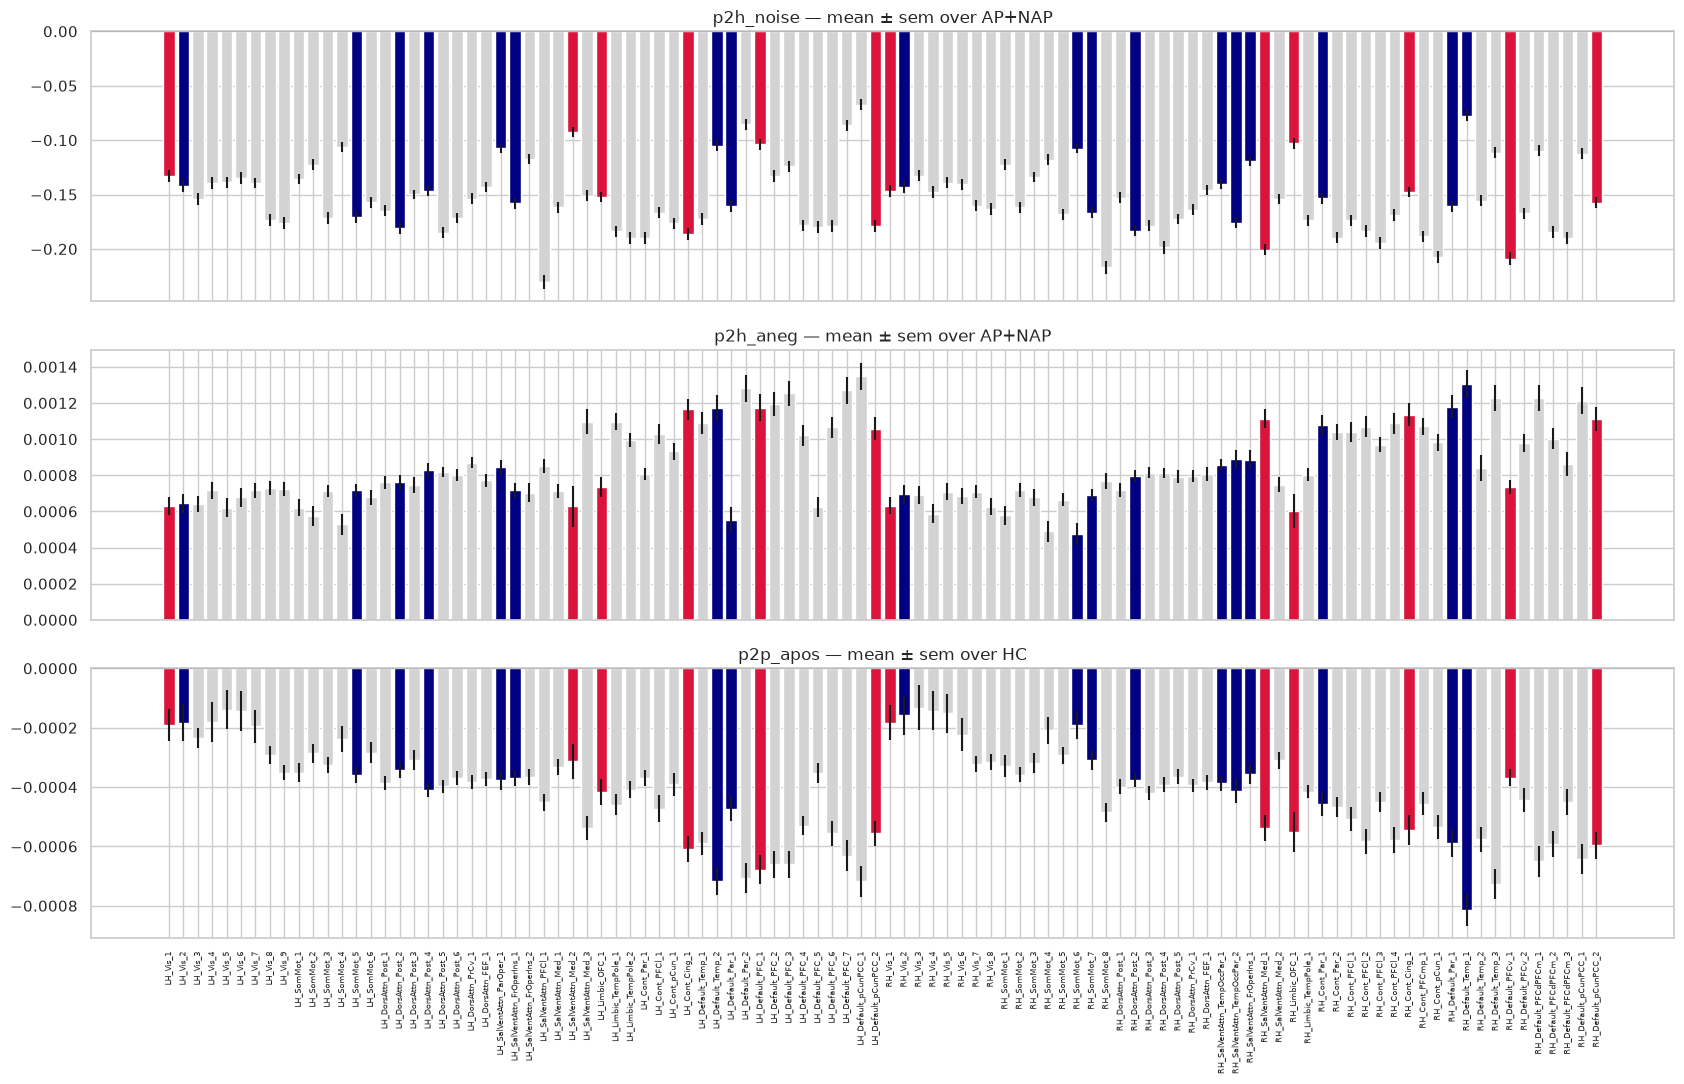

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(17, 11), sharex=True)
for ax, (mapname, who) in zip(axes, (("p2h_noise", ("AP", "NAP")), ("p2h_aneg", ("AP", "NAP")), ("p2p_apos", ("HC",)))):
    M = np.array([res[g][k][mapname] for g in who for k in res[g]])
    cols = ["crimson" if i in rest else ("navy" if i in path else "lightgray") for i in range(100)]
    ax.bar(range(100), M.mean(0), yerr=M.std(0) / np.sqrt(len(M)), color=cols)
    ax.set_title(f"{mapname} — mean ± sem over {'+'.join(who)}"); ax.axhline(0, color="k", lw=.6)
axes[-1].set_xticks(range(100)); axes[-1].set_xticklabels(labels, rotation=90, fontsize=6)
plt.tight_layout(); plt.show()

## Best node per subject

In [4]:
B = pd.read_csv(D / "best_nodes.csv")
for mapname, who in (("p2h_noise", ("AP", "NAP")), ("p2h_aneg", ("AP", "NAP")), ("p2p_apos", ("HC",))):
    b = B[(B["map"] == mapname) & B.group.isin(who)]
    print(f"{mapname} ({'+'.join(who)}):", b.best_label.value_counts().head(6).to_dict(),
          f"| in Mana restorative: {b.in_mana_restorative.mean():.2f}, pathogenic: {b.in_mana_pathogenic.mean():.2f}")

p2h_noise (AP+NAP): {'LH_Default_pCunPCC_1': 48, 'RH_Default_Temp_1': 13, 'LH_SalVentAttn_Med_2': 10, 'LH_SomMot_4': 10, 'LH_Default_Par_2': 4, 'LH_Default_PFC_7': 3} | in Mana restorative: 0.12, pathogenic: 0.19
p2h_aneg (AP+NAP): {'LH_Default_pCunPCC_1': 27, 'RH_Default_Temp_1': 14, 'RH_SalVentAttn_FrOperIns_1': 7, 'RH_Cont_Cing_1': 6, 'LH_SalVentAttn_Med_2': 6, 'LH_Default_PFC_7': 5} | in Mana restorative: 0.18, pathogenic: 0.30
p2p_apos (HC): {'LH_SalVentAttn_Med_2': 9, 'RH_SomMot_6': 4, 'RH_Vis_3': 4, 'LH_Limbic_OFC_1': 4, 'RH_SomMot_4': 3, 'RH_Limbic_OFC_1': 3} | in Mana restorative: 0.38, pathogenic: 0.29


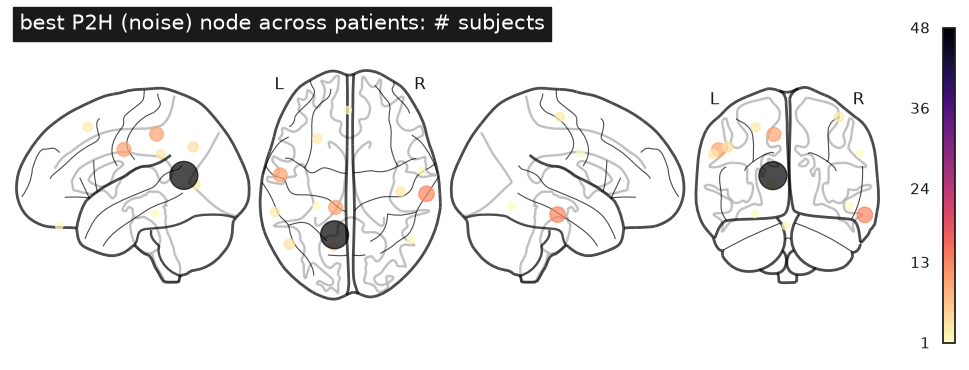

In [5]:
from nilearn import plotting
b = B[(B["map"] == "p2h_noise") & B.group.isin(["AP", "NAP"])]
counts = np.bincount(b.best_node, minlength=100)
sel = counts > 0
plotting.plot_markers(counts[sel], atlas["coords"][sel], node_size=20 + 8 * counts[sel], node_cmap="magma_r",
                      title="best P2H (noise) node across patients: # subjects", display_mode="lzry")
plt.show()

## Map summaries by group and vs symptoms

,measure,mean_HC,mean_AP,mean_NAP,F,p_perm,g_AP_vs_HC,g_NAP_vs_HC,g_NAP_vs_AP,q_FDR
0,p2h_noise_max,-0.0619,-0.0386,-0.0566,3.2711,0.0384,0.6275,0.1376,-0.4780,0.0884
1,p2h_aneg_max,0.0016,0.0017,0.0017,0.5373,0.5885,0.2088,0.1625,-0.0659,0.8442
2,p2o_noise_max,0.3641,0.2939,0.3381,3.1494,0.0442,-0.6389,-0.2251,0.3805,0.0884
3,p2p_apos_max,0.0004,0.0004,0.0004,0.0561,0.9482,-0.0006,0.0525,0.0596,0.9482
4,p2h_noise_mana_rest,-0.1617,-0.1338,-0.1565,3.6206,0.0258,0.6801,0.1174,-0.5110,0.0884
5,p2h_aneg_mana_rest,0.0008,0.0009,0.0009,0.3607,0.7035,0.1762,0.1392,-0.0451,0.8442


,target,measure,rho_partial,p_perm,n,q_FDR
3,PANSS,p2p_apos_max,-0.2020,0.0588,92,0.3527
2,PANSS,p2o_noise_max,0.1535,0.1442,92,0.4103
4,PANSS,p2h_noise_mana_rest,-0.1337,0.2052,92,0.4103
11,YMRS,p2h_aneg_mana_rest,0.1050,0.2965,98,0.6613
8,YMRS,p2o_noise_max,0.1003,0.3375,98,0.6613
0,PANSS,p2h_noise_max,-0.0884,0.4057,92,0.6037
9,YMRS,p2p_apos_max,0.0785,0.4401,98,0.6613
1,PANSS,p2h_aneg_max,-0.0717,0.5031,92,0.6037
7,YMRS,p2h_aneg_max,0.0651,0.5217,98,0.6613
10,YMRS,p2h_noise_mana_rest,-0.0627,0.5511,98,0.6613


/tmp/ipykernel_435004/2558489255.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
/tmp/ipykernel_435004/2558489255.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
/tmp/ipykernel_435004/2558489255.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)


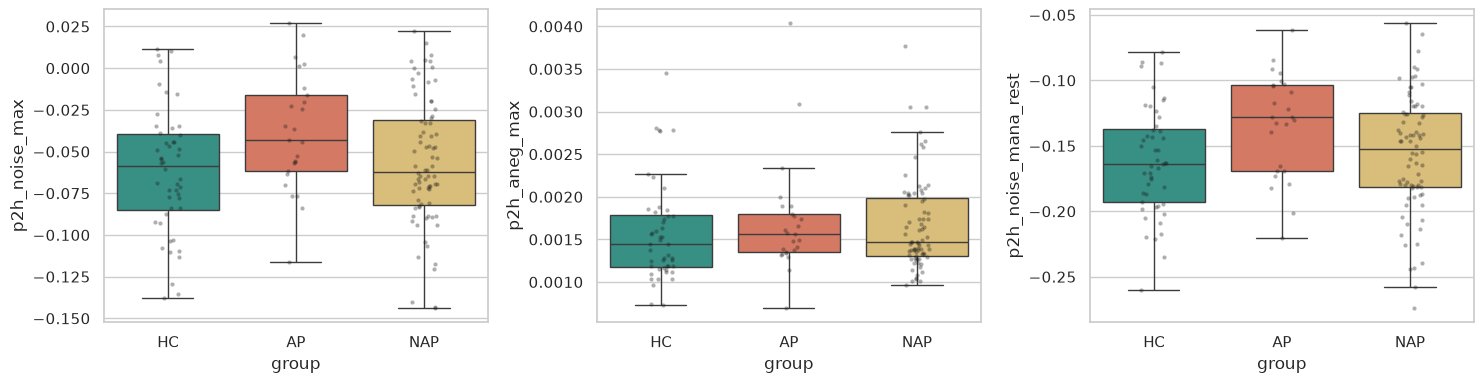

In [6]:
S = pd.read_csv(D / "subject_measures.csv")
display(pd.read_csv(D / "group_tests.csv").round(4))
display(pd.read_csv(D / "symptom_correlations.csv").sort_values("p_perm").round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, ("p2h_noise_max", "p2h_aneg_max", "p2h_noise_mana_rest")):
    sns.boxplot(data=S, x="group", y=m, order=GROUPS, palette=PALETTE, ax=ax, showfliers=False)
    sns.stripplot(data=S, x="group", y=m, order=GROUPS, color="k", alpha=.35, size=3, ax=ax)
plt.tight_layout(); plt.show()